# Notebook 04: SoC speed binning, die-to-SKU optimization and memory repair

**Chip:** an 8-core SoC. One die design is sold as 3 products (SKUs):

| SKU | Good cores needed | Clock | Max power | Price | Weekly demand |
|---|---|---|---|---|---|
| SoC-Pro | 8 | 3.0 GHz | 18 W | $145 | 900 |
| SoC-Std | 6 | 2.6 GHz | 15 W | $95 | 2,200 |
| SoC-Lite | 4 | 2.2 GHz | 10 W | $55 | 2,600 |

Defective or slow cores are **fused off** (harvesting), and each die gets an **AVS voltage bin**.

**Datasets:** `soc_binning_harvesting.csv` (6,160 dies), `soc_sku_demand.csv` (3 SKUs) and `memory_repair_bitmaps.csv` (3,000 cache arrays).

| Task | Question | Method |
|---|---|---|
| **A (main)** | Predict core speed from on-chip monitors, so the long functional speed test can be skipped | ML regression + guard band |
| B | Turn the predicted speed into SKU, AVS bin and power, without causing quality escapes | rebuilt SKU rules |
| C | Assign each die to the SKU that **maximizes revenue against demand** | integer linear programming |
| D | Repair memory with spare rows and columns: greedy vs. exact | optimization algorithms (+ an ML check) |

**Colab:** Runtime → Run all, and upload the dataset zip or the 3 CSVs when asked.

## 0.1 Setup
`scipy.optimize.milp` (already in Colab) solves the integer program in task C.

In [1]:
import importlib, subprocess, sys
for pkg in ["xgboost", "lightgbm"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, glob, zipfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.optimize import milp, LinearConstraint, Bounds

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)
print("Libraries loaded")

Libraries loaded


## 0.2 Load the three datasets

In [2]:
NEEDED = ["soc_binning_harvesting.csv", "soc_sku_demand.csv", "memory_repair_bitmaps.csv"]

def find(name):
    hits = [h for h in glob.glob(f"**/{name}", recursive=True) if "cleaned" not in h]
    return min(hits, key=len) if hits else None

if any(find(f) is None for f in NEEDED):
    try:
        from google.colab import files
        print("Upload the dataset zip or:", NEEDED)
        for fname in files.upload():
            if fname.lower().endswith(".zip"):
                zipfile.ZipFile(fname).extractall("dataset_upload")
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook")

soc = pd.read_csv(find("soc_binning_harvesting.csv"))
sku = pd.read_csv(find("soc_sku_demand.csv"))
repair = pd.read_csv(find("memory_repair_bitmaps.csv"))
print("soc:", soc.shape, "| sku:", sku.shape, "| repair:", repair.shape)
sku

soc: (6160, 52) | sku: (3, 6) | repair: (3000, 13)


,sku,cores,fmax_GHz,tdp_W,price_usd,weekly_demand_units
0,SoC-Pro,8,3.0,18.0,145,900
1,SoC-Std,6,2.6,15.0,95,2200
2,SoC-Lite,4,2.2,10.0,55,2600


## 0.3 Apply the cleaning from notebook 00
- Blank Fmax/Vmin values mean a **defective core**. They stay blank and are never filled in.
- New summary columns: number of good cores, leakage when hot, and the **k-th fastest good core** for k = 8, 6, 4.

That last one matters: an SKU needing k cores runs at the speed of the **slowest of its k best cores**.

In [3]:
FCOLS = [f"core{i}_fmax_GHz" for i in range(8)]
VCOLS = [f"core{i}_vmin_2GHz_mV" for i in range(8)]
soc["n_good_cores"] = soc[FCOLS].notna().sum(axis=1)
soc["leak_hot_A"] = soc.iddq_25C_mA * 22 / 1000          # leakage at hot (design rule from the spec)
fsorted = -np.sort(-soc[FCOLS].fillna(-1).values, axis=1)  # fastest first, defective = -1
for k in (8, 6, 4):
    soc[f"f_top{k}"] = np.where(fsorted[:, k - 1] > 0, fsorted[:, k - 1], np.nan)
soc["vmin_worst_mV"] = soc[VCOLS].max(axis=1)
print("Good cores per die:", soc.n_good_cores.value_counts().sort_index().to_dict())
soc[["die_id", "n_good_cores", "f_top8", "f_top6", "f_top4", "sku_rule_based"]].head()

Good cores per die: {2: 1, 3: 9, 4: 57, 5: 285, 6: 1002, 7: 2180, 8: 2626}


,die_id,n_good_cores,f_top8,f_top6,f_top4,sku_rule_based
0,SOC-000000,7,NaN,2.6816,2.6922,SoC-Std
1,SOC-000001,6,NaN,2.5688,2.6690,SoC-Std
2,SOC-000002,8,2.6866,2.7062,2.7180,SoC-Std
3,SOC-000003,7,NaN,2.7620,2.7880,SoC-Std
4,SOC-000004,7,NaN,2.6529,2.6764,SoC-Std


# Part 1: Focused EDA

## 1.1 Monitors vs. speed
The ring oscillator (RO), critical-path monitor (CPM) and leakage (IDDQ) are cheap to measure. If they track core speed, the long functional speed test can be replaced.

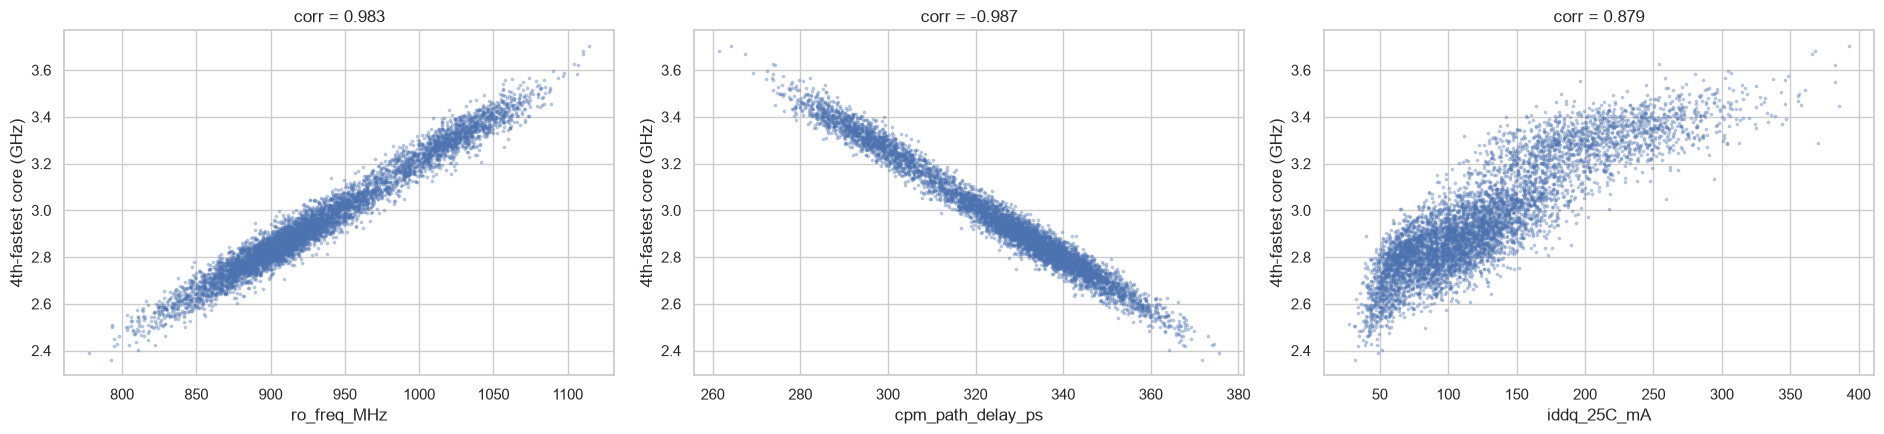

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
for a, x in zip(ax, ["ro_freq_MHz", "cpm_path_delay_ps", "iddq_25C_mA"]):
    a.scatter(soc[x], soc.f_top4, s=3, alpha=0.3)
    a.set(xlabel=x, ylabel="4th-fastest core (GHz)", title=f"corr = {soc[x].corr(soc.f_top4):.3f}")
plt.tight_layout(); plt.show()

## 1.2 Core-to-core variation inside one die
Cores on the same die differ a little. That part is random and the monitors can't see it, so it sets a floor on how exactly per-die speed can be predicted.

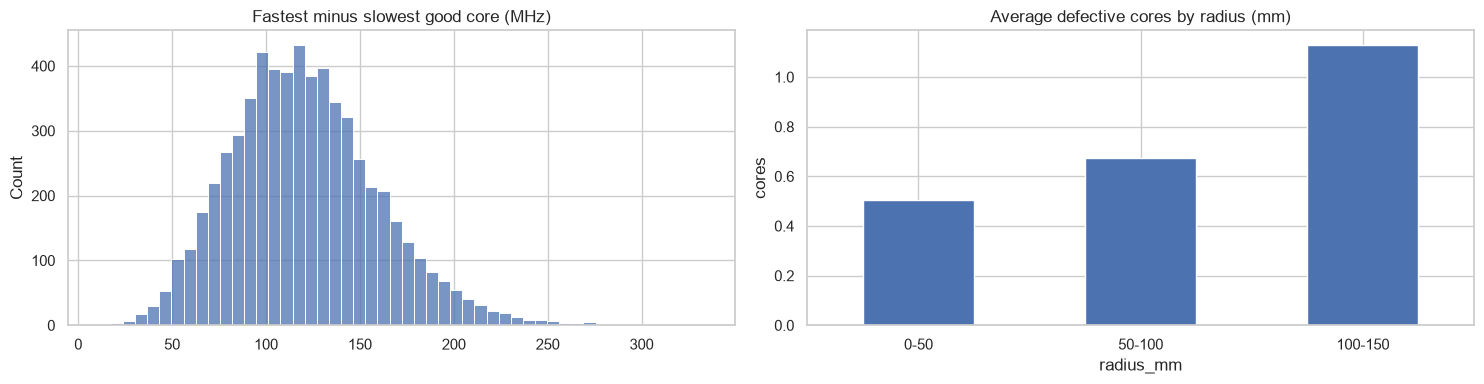

Median core spread inside a die: 118 MHz


In [5]:
spread = (soc[FCOLS].max(axis=1) - soc[FCOLS].min(axis=1)) * 1000
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(spread, bins=50, ax=ax[0]); ax[0].set_title("Fastest minus slowest good core (MHz)")
zone = pd.cut(soc.radius_mm, [0, 50, 100, 150, 200], labels=["0-50", "50-100", "100-150", "150+"])
soc.groupby(zone, observed=True).n_good_cores.apply(lambda s: (8 - s).mean()).plot.bar(ax=ax[1], rot=0)
ax[1].set(title="Average defective cores by radius (mm)", ylabel="cores")
plt.tight_layout(); plt.show()
print(f"Median core spread inside a die: {spread.median():.0f} MHz")

## 1.3 Supply vs. demand: the business problem
The rule-based flow gives every die the **best** SKU it can make. Too many Std dies come out and far too few Lite.

          price_usd  weekly_demand_units  supply_units  demand_share_%  supply_share_%
sku                                                                                   
SoC-Pro         145                  900           886            15.8            14.4
SoC-Std          95                 2200          4909            38.6            79.7
SoC-Lite         55                 2600           349            45.6             5.7


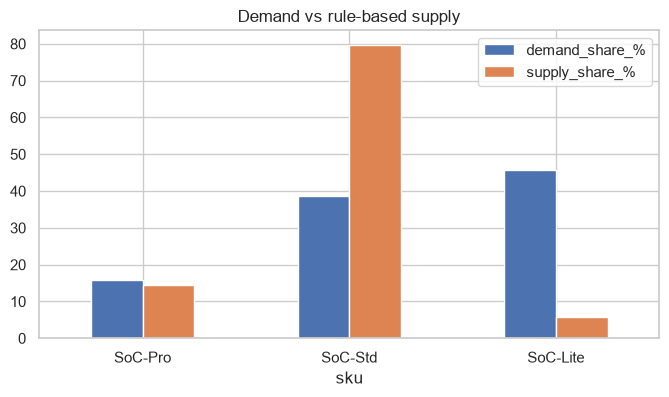

In [6]:
mix = sku.set_index("sku")[["price_usd", "weekly_demand_units"]].copy()
mix["supply_units"] = soc.sku_rule_based.value_counts().reindex(mix.index)
mix["demand_share_%"] = mix.weekly_demand_units / mix.weekly_demand_units.sum() * 100
mix["supply_share_%"] = mix.supply_units / len(soc) * 100
print(mix.round(1).to_string())
mix[["demand_share_%", "supply_share_%"]].plot.bar(figsize=(8, 4), rot=0, title="Demand vs rule-based supply"); plt.show()

# Part 2: Rebuild the SKU rules
To test predictions and optimize assignments, we need the binning rules as code. From the product specification, a die qualifies for an SKU when:
1. its L2 cache is repairable
2. it has at least k good cores; the k fastest are used and the others are fused off
3. the voltage needed to reach the SKU clock, `0.85 V × (clock / slowest core)^0.8`, is at most 0.90 V
4. the voltage is rounded up to an AVS bin (0.75 V + 12.5 mV steps, minimum 0.76 V)
5. power at that voltage, `k × 0.62 × (V/0.85)² × clock + hot leakage × V`, is within the SKU's max power (TDP)

We check that this rebuilds the dataset's `sku_rule_based` column.

In [7]:
SKUS = sku.set_index("sku")
ORDER = ["SoC-Pro", "SoC-Std", "SoC-Lite"]
PRICE = SKUS.price_usd.to_dict()

def eligibility(df, ftop=None, guard_GHz=0.0):
    # Per SKU: eligible?, AVS bin, power. ftop = {k: k-th fastest core speed}; defaults to the measured values.
    out = {}
    for s in ORDER:
        k, f, tdp = int(SKUS.loc[s, "cores"]), SKUS.loc[s, "fmax_GHz"], SKUS.loc[s, "tdp_W"]
        fslow = (df[f"f_top{k}"].values if ftop is None else ftop[k]) - guard_GHz
        with np.errstate(invalid="ignore", divide="ignore"):
            v = np.maximum(0.85 * (f / fslow) ** 0.8, 0.76)
            b = np.ceil((v - 0.75) / 0.0125 - 1e-9)
            vb = 0.75 + b * 0.0125
            p = k * 0.62 * (vb / 0.85) ** 2 * f + df.leak_hot_A.values * vb
            ok = df.l2_repairable.values & np.isfinite(fslow) & (0.85 * (f / fslow) ** 0.8 <= 0.90) & (p <= tdp)
        out[s] = ok; out[s + "_bin"] = np.where(ok, b, -1); out[s + "_W"] = np.where(ok, p, np.nan)
    return pd.DataFrame(out, index=df.index)

def best_sku(elig):  # rule-based: highest SKU the die qualifies for
    return np.select([elig[s] for s in ORDER], ORDER, default="scrap")

true_elig = eligibility(soc)
soc["sku_rebuilt"] = best_sku(true_elig)
print(f"Rebuilt rules match sku_rule_based on {(soc.sku_rebuilt == soc.sku_rule_based).mean():.2%} of dies")
print("Eligible dies per SKU (a die can qualify for several):", {s: int(true_elig[s].sum()) for s in ORDER})

Rebuilt rules match sku_rule_based on 100.00% of dies
Eligible dies per SKU (a die can qualify for several): {'SoC-Pro': 886, 'SoC-Std': 5795, 'SoC-Lite': 6125}


# Part 3, Task A (main): predict core speed from monitors

## 3.1 Split by wafer
20 wafers. 5 are held out for testing, and whole wafers stay on one side.

In [8]:
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(soc, groups=soc.wafer_id))
train, test = soc.iloc[tr_idx].reset_index(drop=True), soc.iloc[te_idx].reset_index(drop=True)
print(f"Train: {len(train)} dies, {train.wafer_id.nunique()} wafers | Test: {len(test)} dies, {test.wafer_id.nunique()} wafers")

Train: 4620 dies, 15 wafers | Test: 1540 dies, 5 wafers


## 3.2 Targets and features
- **Targets:** `f_top8`, `f_top6` and `f_top4`, the speed of the slowest core an SKU would use. They are trained only on dies that have enough good cores.
- **Features:** the RO, CPM and IDDQ monitors, PCM, position, and the number of good cores. **Which** cores are defective comes from the fast structural test, which is still run.

Metrics: R², MAE in **MHz**, and the share of dies predicted within ±20 MHz.

In [9]:
PCM = ["pcm_vth_n_mV", "pcm_vth_p_mV", "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
POS = ["x_mm", "y_mm", "radius_mm"]
BASE_FEATS = ["ro_freq_MHz", "cpm_path_delay_ps", "iddq_25C_mA", "n_good_cores"] + PCM + POS
KS = [8, 6, 4]

def make_models():
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                                colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
        "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1),
        "MLP": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000,
                                                            early_stopping=True, random_state=SEED)),
    }

def speed_eval(name, k, y, p):
    e = np.abs(y - p) * 1000
    return {"model": name, "target": f"f_top{k}", "R2": r2_score(y, p), "MAE_MHz": e.mean(),
            "P95_err_MHz": np.percentile(e, 95), "within20MHz_%": (e <= 20).mean() * 100}

def fit_all(feats, tr, tag=""):
    rows, models = [], {}
    for name in make_models():
        for k in KS:
            a, b = tr[tr[f"f_top{k}"].notna()], test[test[f"f_top{k}"].notna()]
            m = make_models()[name].fit(a[feats], a[f"f_top{k}"])
            models[(name + tag, k)] = m
            rows.append(speed_eval(name + tag, k, b[f"f_top{k}"], m.predict(b[feats])))
    return pd.DataFrame(rows), models

res_A, fitted = fit_all(BASE_FEATS, train)
print(res_A.pivot(index="model", columns="target", values="MAE_MHz").round(2).to_string())
print("\nR2:\n" + res_A.pivot(index="model", columns="target", values="R2").round(4).to_string())

target        f_top4  f_top6  f_top8
model                               
LightGBM       24.74   25.99   29.21
MLP            30.24   36.04   42.32
RandomForest   26.89   27.65   29.62
Ridge          19.47   20.15   22.41
XGBoost        24.53   25.41   28.26

R2:
target        f_top4  f_top6  f_top8
model                               
LightGBM      0.9854  0.9842  0.9791
MLP           0.9797  0.9695  0.9580
RandomForest  0.9832  0.9820  0.9781
Ridge         0.9918  0.9908  0.9882
XGBoost       0.9859  0.9847  0.9800


## 3.3 Feature engineering and tuning
- **Physics features:** the RO speed vs. CPM delay ratio (two views of the same transistor speed), and log(IDDQ), because leakage grows exponentially with process.
- **Tuning:** the top two models, with 4-fold GroupKFold by wafer.

In [10]:
for d in (soc, train, test):
    d["ro_x_cpm"] = d.ro_freq_MHz / d.cpm_path_delay_ps
    d["log_iddq"] = np.log(d.iddq_25C_mA)
FE_FEATS = BASE_FEATS + ["ro_x_cpm", "log_iddq"]
res_FE, m_fe = fit_all(FE_FEATS, train, " +FE"); fitted.update(m_fe)

GRIDS = {
    "Ridge": {"ridge__alpha": np.logspace(-3, 2, 20)},
    "RandomForest": {"n_estimators": [200, 400], "max_depth": [None, 12, 20], "min_samples_leaf": [1, 3, 5, 10]},
    "XGBoost": {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 5],
                "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.6, 0.8, 1.0]},
    "LightGBM": {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "num_leaves": [7, 15, 31],
                 "min_child_samples": [10, 20, 40], "subsample": [0.7, 0.85, 1.0], "subsample_freq": [1]},
    "MLP": {"mlpregressor__hidden_layer_sizes": [(64, 32), (128, 64)], "mlpregressor__alpha": [1e-4, 1e-3, 1e-2]},
}
top2 = res_FE.groupby("model").MAE_MHz.mean().sort_values().index[:2].str.replace(" +FE", "", regex=False)
rows = []
for name in top2:
    for k in KS:
        a, b = train[train[f"f_top{k}"].notna()], test[test[f"f_top{k}"].notna()]
        s = RandomizedSearchCV(make_models()[name], GRIDS[name], n_iter=10, cv=GroupKFold(n_splits=4),
                               scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
        s.fit(a[FE_FEATS], a[f"f_top{k}"], groups=a.wafer_id)
        fitted[(name + " +FE +tuned", k)] = s.best_estimator_
        rows.append(speed_eval(name + " +FE +tuned", k, b[f"f_top{k}"], s.best_estimator_.predict(b[FE_FEATS])))
allA = pd.concat([res_A, res_FE, pd.DataFrame(rows)], ignore_index=True)
summary_A = allA.groupby("model")[["R2", "MAE_MHz", "P95_err_MHz", "within20MHz_%"]].mean().sort_values("MAE_MHz")
print("Average over the 3 targets:\n" + summary_A.round(3).to_string())

Average over the 3 targets:
                       R2  MAE_MHz  P95_err_MHz  within20MHz_%
model                                                         
Ridge +FE           0.990   20.612       52.145         56.833
Ridge +FE +tuned    0.990   20.613       52.172         56.803
Ridge               0.990   20.677       51.962         56.408
XGBoost +FE         0.984   25.987       63.977         47.938
XGBoost             0.984   26.065       65.046         48.080
XGBoost +FE +tuned  0.983   26.344       65.993         47.464
LightGBM            0.983   26.645       66.723         47.678
LightGBM +FE        0.983   26.663       66.576         47.067
RandomForest +FE    0.982   27.423       68.554         45.315
RandomForest        0.981   28.054       71.041         45.141
MLP                 0.969   36.197       92.857         35.445
MLP +FE             0.962   38.514       97.771         36.089


## 3.4 Final speed model
The lowest average MAE wins.

Final speed model: Ridge +FE
    model target    R2  MAE_MHz  P95_err_MHz  within20MHz_%
Ridge +FE f_top8 0.988   22.554       56.313         52.403
Ridge +FE f_top6 0.991   20.018       52.333         58.096
Ridge +FE f_top4 0.992   19.266       47.788         60.000


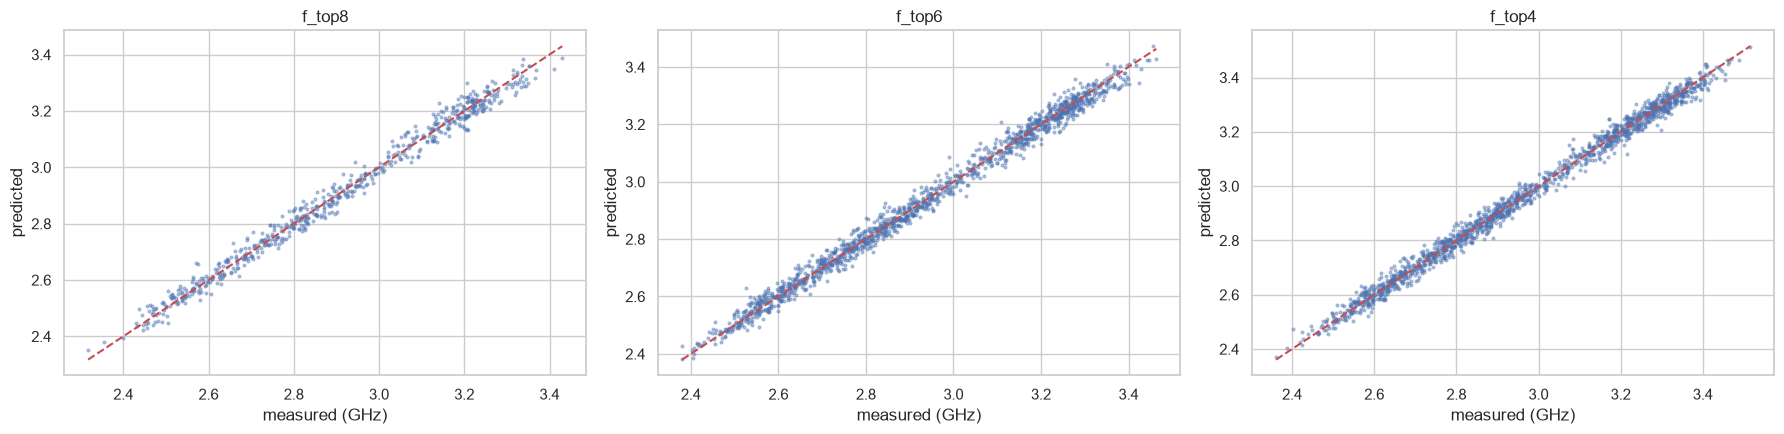

In [11]:
FINAL_A = summary_A.index[0]
feats_of = lambda m: FE_FEATS if "+FE" in m else BASE_FEATS
print("Final speed model:", FINAL_A)
print(allA[allA.model == FINAL_A].round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, k in zip(ax, KS):
    b = test[test[f"f_top{k}"].notna()]
    p = fitted[(FINAL_A, k)].predict(b[feats_of(FINAL_A)])
    a.scatter(b[f"f_top{k}"], p, s=4, alpha=0.4); lim = [b[f"f_top{k}"].min(), b[f"f_top{k}"].max()]
    a.plot(lim, lim, "r--"); a.set(xlabel="measured (GHz)", ylabel="predicted", title=f"f_top{k}")
plt.tight_layout(); plt.show()

# Part 4, Task B: from predicted speed to SKU, without quality escapes
A predicted speed is never exact. If we assign a die to an SKU it can't really meet, that is a **quality escape**: the worst outcome. So we subtract a **guard band** from the predicted speed before applying the rules.

For each guard band, on the test wafers:
- **Escape %:** dies whose assignment is unsafe: either an SKU they don't truly qualify for, or an AVS voltage bin **lower** than they really need (too little voltage means a failing part). This must be about 0.
- **Under-bin %:** dies assigned a lower SKU than they could have had (lost revenue)
- **Revenue per die:** with the rule-based "best SKU" policy

In [12]:
pred_ftop = {k: np.where(test[f"f_top{k}"].notna(), fitted[(FINAL_A, k)].predict(test[feats_of(FINAL_A)]), np.nan)
             for k in KS}
true_test = best_sku(eligibility(test))
rank_of = {"scrap": 0, "SoC-Lite": 1, "SoC-Std": 2, "SoC-Pro": 3}
true_rank = pd.Series(true_test).map(rank_of).values
rev_true = pd.Series(true_test).map(PRICE).fillna(0).mean()
te_true = eligibility(test)

def unsafe(assigned_sku, pred_e):
    # assigned SKU not truly met, or predicted voltage bin below the bin the die really needs
    bad = np.zeros(len(assigned_sku), bool)
    for s in ORDER:
        m = np.asarray(assigned_sku) == s
        bad[m] = ~te_true[s].values[m] | (pred_e[s + "_bin"].values[m] < te_true[s + "_bin"].values[m])
    return bad

rows = []
for g in [0, 10, 20, 30, 40, 60, 80, 100]:
    pe_g = eligibility(test, pred_ftop, g / 1000)
    pred_sku = best_sku(pe_g)
    pr = pd.Series(pred_sku).map(rank_of).values
    rows.append({"guard_band_MHz": g, "SKU_match_%": (pred_sku == true_test).mean() * 100,
                 "escape_%": unsafe(pred_sku, pe_g).mean() * 100, "under_bin_%": (pr < true_rank).mean() * 100,
                 "revenue_per_die_$": pd.Series(pred_sku).map(PRICE).fillna(0).mean()})
gb = pd.DataFrame(rows)
print(f"Revenue per die with full speed testing: ${rev_true:.2f}\n")
print(gb.round(3).to_string(index=False))

Revenue per die with full speed testing: $99.35

 guard_band_MHz  SKU_match_%  escape_%  under_bin_%  revenue_per_die_$
              0       97.662    14.156        1.104             99.383
             10       97.338     9.221        1.623             99.039
             20       97.143     5.455        2.338             98.455
             30       97.013     2.792        2.857             98.013
             40       96.169     1.623        3.766             97.552
             60       94.675     0.325        5.325             96.812
             80       92.078     0.000        7.922             95.649
            100       90.065     0.000        9.935             94.753


## 4.1 Choose the guard band
The smallest guard band with **escapes ≤ 0.1%**. Also shown: how often the predicted AVS voltage bin matches the bin from full testing.

Chosen guard band: 80 MHz
Escapes 0.00% | revenue per die $95.65 vs $99.35 with full testing
AVS bin (same SKU): exact 34.4% | predicted bin higher (safe, more voltage) 65.6% | lower (unsafe) 0.0%


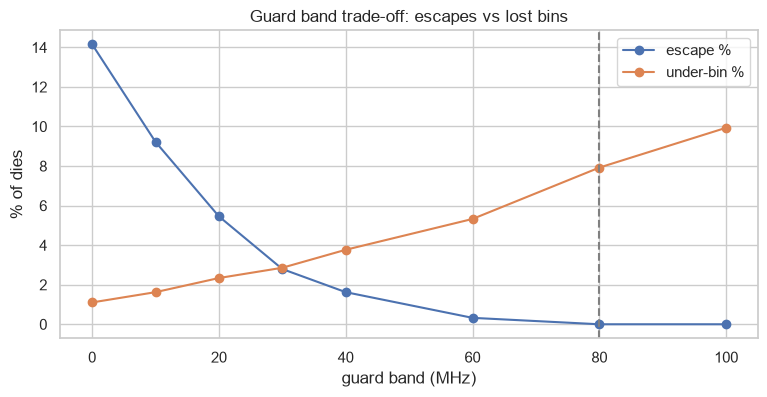

In [13]:
GUARD = int(gb[gb["escape_%"] <= 0.1].guard_band_MHz.min())
pe = eligibility(test, pred_ftop, GUARD / 1000)
psku = best_sku(pe)
same = (psku == true_test) & (psku != "scrap")
bin_diff = np.array([pe.loc[i, s + "_bin"] - te_true.loc[i, s + "_bin"] for i, s in zip(np.where(same)[0], psku[same])])
print(f"Chosen guard band: {GUARD} MHz")
print(f"Escapes {gb.set_index('guard_band_MHz').loc[GUARD, 'escape_%']:.2f}% | revenue per die "
      f"${gb.set_index('guard_band_MHz').loc[GUARD, 'revenue_per_die_$']:.2f} vs ${rev_true:.2f} with full testing")
print(f"AVS bin (same SKU): exact {np.mean(bin_diff == 0):.1%} | predicted bin higher (safe, more voltage) "
      f"{np.mean(bin_diff > 0):.1%} | lower (unsafe) {np.mean(bin_diff < 0):.1%}")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(gb.guard_band_MHz, gb["escape_%"], marker="o", label="escape %")
ax.plot(gb.guard_band_MHz, gb["under_bin_%"], marker="o", label="under-bin %")
ax.axvline(GUARD, ls="--", color="grey"); ax.set(xlabel="guard band (MHz)", ylabel="% of dies"); ax.legend()
ax.set_title("Guard band trade-off: escapes vs lost bins"); plt.show()

## 4.2 Test-time saving
The functional speed test takes about 450 ms per die. With prediction, it runs only on a monitoring sample (5% assumed) to check the model and retrain it.

In [14]:
conv_ms = soc.conv_speed_test_time_ms.mean()
for keep in [0.05, 0.10]:
    print(f"Keep {keep:.0%} sampled: {conv_ms:.0f} ms -> {keep * conv_ms:.0f} ms per die ({100 * (1 - keep):.0f}% of speed-test time saved)")

Keep 5% sampled: 450 ms -> 23 ms per die (95% of speed-test time saved)
Keep 10% sampled: 450 ms -> 45 ms per die (90% of speed-test time saved)


## 4.3 Is skipping the speed test worth it?
Compares the tester time saved with the revenue lost to the guard band. The tester cost per second is an **assumption** (typical ATE cost is a few cents per second); change `TESTER_USD_PER_S` to your own figure.

In [15]:
TESTER_USD_PER_S = 0.05
gbi = gb.set_index("guard_band_MHz")
saved_usd = conv_ms / 1000 * 0.95 * TESTER_USD_PER_S
lost_usd = rev_true - gbi.loc[GUARD, "revenue_per_die_$"]
print(f"Tester cost saved by skipping 95% of speed tests: ${saved_usd:.3f} per die")
print(f"Revenue lost to the {GUARD} MHz guard band       : ${lost_usd:.2f} per die")
print("Verdict:", "skip the speed test" if saved_usd > lost_usd else
      "KEEP the functional speed test: the guard band costs far more than the test time saved")

Tester cost saved by skipping 95% of speed tests: $0.021 per die
Revenue lost to the 80 MHz guard band       : $3.70 per die
Verdict: KEEP the functional speed test: the guard band costs far more than the test time saved


# Part 5, Task C: die-to-SKU optimization against demand

The rule-based flow ignores demand: it makes too many Std and too few Lite. Unsold units earn nothing.

**Integer linear program:**
- **Decide** how many dies of each *eligibility group* (the set of SKUs a die qualifies for) to sell as each SKU.
- **Maximize** total revenue = Σ price × units sold.
- **Subject to:** units of each SKU ≤ demand, each die is used at most once, and a die is only sold as an SKU it qualifies for.

A Std-capable die can be sold as Lite when Lite is short. That down-binning is where the extra revenue comes from.

The weekly demand is scaled to the number of dies in the batch.

In [16]:
def optimize(elig, n_dies_total):
    demand = (SKUS.weekly_demand_units * n_dies_total / len(soc)).round().astype(int)
    pattern = elig[ORDER].apply(lambda r: tuple(s for s in ORDER if r[s]), axis=1)
    groups = pattern.value_counts()
    var = [(g, s) for g in groups.index for s in g]               # (group, sku) pairs that are allowed
    c = -np.array([PRICE[s] for _, s in var], float)             # milp minimizes -> negative revenue
    A_sku = np.array([[1 if s == t else 0 for _, s in var] for t in ORDER])
    A_grp = np.array([[1 if g == h else 0 for g, _ in var] for h in groups.index])
    cons = [LinearConstraint(A_sku, 0, demand[ORDER].values), LinearConstraint(A_grp, 0, groups.values)]
    sol = milp(c, constraints=cons, integrality=np.ones(len(var)), bounds=Bounds(0, np.inf))
    alloc = pd.Series(sol.x.round().astype(int), index=pd.MultiIndex.from_tuples(var, names=["group", "sku"]))
    return alloc, demand, pattern

def rule_revenue(sku_list, n_dies_total):
    demand = (SKUS.weekly_demand_units * n_dies_total / len(soc)).round()
    made = pd.Series(sku_list).value_counts().reindex(ORDER).fillna(0)
    sold = np.minimum(made, demand[ORDER])
    return (sold * SKUS.price_usd[ORDER]).sum(), made, sold

rev_rule, made, sold = rule_revenue(soc.sku_rebuilt, len(soc))
alloc, demand, pattern = optimize(true_elig, len(soc))
opt_units = alloc.groupby(level="sku").sum().reindex(ORDER)
rev_opt = (opt_units * SKUS.price_usd[ORDER]).sum()
table = pd.DataFrame({"demand": demand[ORDER], "rule_made": made, "rule_sold": sold, "optimized_sold": opt_units})
print(table.astype(int).to_string())
print(f"\nRevenue, rule-based: ${rev_rule:,.0f} | optimized: ${rev_opt:,.0f} | gain: ${rev_opt - rev_rule:,.0f} "
      f"(+{100 * (rev_opt / rev_rule - 1):.1f}%) on {len(soc):,} dies")
print("Eligibility groups:", pattern.value_counts().to_dict())

          demand  rule_made  rule_sold  optimized_sold
SoC-Pro      900        886        886             886
SoC-Std     2200       4909       2200            2200
SoC-Lite    2600        349        349            2600

Revenue, rule-based: $356,665 | optimized: $480,470 | gain: $123,805 (+34.7%) on 6,160 dies
Eligibility groups: {('SoC-Std', 'SoC-Lite'): 4892, ('SoC-Pro', 'SoC-Std', 'SoC-Lite'): 884, ('SoC-Lite',): 349, ('SoC-Std',): 17, (): 16, ('SoC-Pro', 'SoC-Std'): 2}


## 5.1 Optimization on **predicted** eligibility (the full AI flow)
On the test wafers we run the optimizer on **predicted** eligibility (with the guard band) and check every assignment against the **true** eligibility, to confirm there are no escapes.

In [17]:
alloc_p, _, pattern_p = optimize(pe, len(test))
# hand out the allocation die by die and check true eligibility
assigned = pd.Series("unsold", index=test.index)
for (g, s), n in alloc_p.items():
    idx = pattern_p[(pattern_p == g) & (assigned.loc[pattern_p.index] == "unsold")].index[:n]
    assigned.loc[idx] = s
escapes = int(unsafe(assigned.where(assigned != "unsold", "scrap").values, pe).sum())
rev_ai = assigned.map(PRICE).fillna(0).sum()
alloc_t, _, _ = optimize(te_true, len(test))
rev_full = (alloc_t.groupby(level="sku").sum().reindex(ORDER) * SKUS.price_usd[ORDER]).sum()
rev_rule_t, _, _ = rule_revenue(true_test, len(test))
print(f"Test wafers ({len(test)} dies):")
print(f"  rule-based, full speed test : ${rev_rule_t:,.0f}")
print(f"  optimized,  full speed test : ${rev_full:,.0f}")
print(f"  optimized,  AI prediction   : ${rev_ai:,.0f}  (unsafe assignments: {escapes} of {len(test)})")

Test wafers (1540 dies):
  rule-based, full speed test : $90,870
  optimized,  full speed test : $120,625
  optimized,  AI prediction   : $108,735  (unsafe assignments: 0 of 1540)


# Part 6, Task D: memory repair (greedy vs. exact)
Each 512 × 512 cache array has **4 spare rows and 4 spare columns**. Every failing cell must be covered by a spare row or a spare column.
- **Greedy:** repeatedly replace the line with the most fails. Fast, but can get stuck.
- **Exact:** first replace "must-repair" lines (a row with more fails than the spare columns left), then search the remaining choices (branch and bound). It finds a solution whenever one exists.

## 6.1 Parse the fail bitmaps

In [18]:
def parse(s):
    return set() if pd.isna(s) else {tuple(map(int, c.split(":"))) for c in s.split(";")}
repair["fails"] = repair.fail_cells.apply(parse)
print("Parsed counts match n_fail_cells:", (repair.fails.apply(len) == repair.n_fail_cells).all())

Parsed counts match n_fail_cells: True


## 6.2 The two algorithms

In [19]:
def greedy_repair(fails, sr=4, sc=4):
    fails = set(fails)
    while fails and (sr or sc):
        rc, cc = pd.Series([r for r, _ in fails]).value_counts(), pd.Series([c for _, c in fails]).value_counts()
        br = (rc.index[0], rc.iloc[0]) if sr else (None, -1)
        bc = (cc.index[0], cc.iloc[0]) if sc else (None, -1)
        if br[1] >= bc[1]:
            fails = {f for f in fails if f[0] != br[0]}; sr -= 1
        else:
            fails = {f for f in fails if f[1] != bc[0]}; sc -= 1
    return not fails

def exact_repair(fails, sr=4, sc=4):
    if not fails:
        return True
    rows, cols = {}, {}
    for r, c in fails:
        rows.setdefault(r, set()).add(c); cols.setdefault(c, set()).add(r)
    for r, cs in rows.items():                      # must-repair row
        if len(cs) > sc:
            return sr > 0 and exact_repair({f for f in fails if f[0] != r}, sr - 1, sc)
    for c, rs in cols.items():                      # must-repair column
        if len(rs) > sr:
            return sc > 0 and exact_repair({f for f in fails if f[1] != c}, sr, sc - 1)
    if len(fails) > 2 * sr * sc:                    # bound: too many fails left
        return False
    r, c = min(fails)                               # branch: this cell needs its row or its column
    return (sr > 0 and exact_repair({f for f in fails if f[0] != r}, sr - 1, sc)) or \
           (sc > 0 and exact_repair({f for f in fails if f[1] != c}, sr, sc - 1))

t0 = time.time(); repair["greedy_ok"] = repair.fails.apply(greedy_repair); t_g = time.time() - t0
t0 = time.time(); repair["exact_ok"] = repair.fails.apply(exact_repair); t_e = time.time() - t0
print(f"Greedy matches dataset label: {(repair.greedy_ok == repair.greedy_repairable).mean():.2%} ({t_g / len(repair) * 1000:.2f} ms/array)")
print(f"Exact  matches dataset label: {(repair.exact_ok == repair.optimal_repairable).mean():.2%} ({t_e / len(repair) * 1000:.2f} ms/array)")

Greedy matches dataset label: 100.00% (1.76 ms/array)
Exact  matches dataset label: 100.00% (0.07 ms/array)


## 6.3 Yield gain

Repairable: greedy 61.4% | exact 62.0% | arrays saved by exact: 17 of 3000
Exact ever worse than greedy: 0


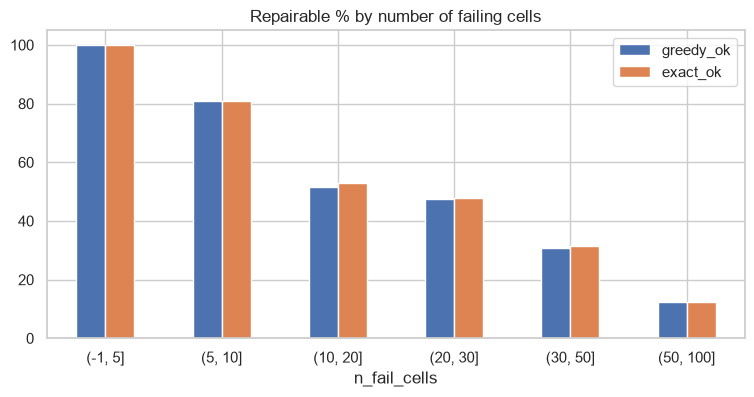

In [20]:
g, e = repair.greedy_ok.mean(), repair.exact_ok.mean()
saved = (repair.exact_ok & ~repair.greedy_ok).sum()
print(f"Repairable: greedy {g:.1%} | exact {e:.1%} | arrays saved by exact: {saved} of {len(repair)}")
print("Exact ever worse than greedy:", int((repair.greedy_ok & ~repair.exact_ok).sum()))
bins = pd.cut(repair.n_fail_cells, [-1, 5, 10, 20, 30, 50, 100])
repair.groupby(bins, observed=True)[["greedy_ok", "exact_ok"]].mean().mul(100).plot.bar(
    figsize=(9, 4), rot=0, title="Repairable % by number of failing cells"); plt.show()

## 6.4 Could ML replace the solver?
A Random Forest classifier that predicts "repairable" from simple bitmap counts, scored with 5-fold cross-validation, compared with the exact solver (always right by construction).

In [21]:
def bitmap_features(f):
    if not f:
        return dict(n=0, rows=0, cols=0, max_row=0, max_col=0, must_rows=0, must_cols=0)
    r, c = pd.Series([a for a, _ in f]).value_counts(), pd.Series([b for _, b in f]).value_counts()
    return dict(n=len(f), rows=len(r), cols=len(c), max_row=r.max(), max_col=c.max(),
                must_rows=(r > 4).sum(), must_cols=(c > 4).sum())
X = pd.DataFrame(list(repair.fails.apply(bitmap_features)))
p = cross_val_predict(RandomForestClassifier(n_estimators=300, random_state=SEED), X, repair.exact_ok,
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
print(f"ML accuracy: {accuracy_score(repair.exact_ok, p):.1%} | wrongly says repairable: {(p & ~repair.exact_ok).sum()} arrays")
print(f"Exact solver: 100% by construction, {t_e / len(repair) * 1000:.2f} ms per array")

ML accuracy: 97.5% | wrongly says repairable: 22 arrays
Exact solver: 100% by construction, 0.07 ms per array


# Part 7: Save the models

In [22]:
bundle = {"speed_models": {k: fitted[(FINAL_A, k)] for k in KS}, "speed_model_name": FINAL_A,
          "features": feats_of(FINAL_A), "guard_band_MHz": GUARD, "sku_table": sku}
joblib.dump(bundle, "soc_models.joblib", compress=3)
print("Saved soc_models.joblib:", round(os.path.getsize("soc_models.joblib") / 1e3, 1), "KB")

Saved soc_models.joblib: 3.2 KB


# Part 8: Would deep learning, GANs or reinforcement learning help here?

- **Deep learning (MLP):** the **worst** speed model (MAE about 36 MHz vs. 21 MHz for Ridge). Core speed follows the monitors almost linearly, so **Ridge won again** (R² ≈ 0.99).
- **The real limit:** cores on one die differ by about 118 MHz at random. The monitors measure the die, not each core, so no model can predict which core is slowest. That is why a large guard band is needed.
- **GAN:** fake dies add no information about real core variation, and they can't be used to justify fusing decisions.
- **RNN / LSTM:** no sequences in the data.
- **Reinforcement learning:** die-to-SKU assignment *is* a decision problem, but it has an exact mathematical form. **Integer linear programming solves it optimally in milliseconds**; RL would only approximate that answer.
- **Memory repair:** the exact branch-and-bound solver is always right and fast (0.07 ms per array). An ML classifier got 97.5% and wrongly called 22 unrepairable arrays repairable, which would be escapes. **Use the solver, not ML.**

# Part 9: Summary: what was chosen and why

| Task | Chosen method | Result | Why |
|---|---|---|---|
| A. Core speed from monitors | **Ridge regression** (+ physics features) | R² 0.988–0.992, MAE 19–23 MHz | Best of 5 models; near-linear physics; 3 KB model |
| B. Predicted SKU and voltage bin | Rebuilt SKU rules + **80 MHz guard band** | **0 unsafe assignments**; revenue $95.65 vs $99.35 per die | The guard band is what makes prediction safe |
| B. Skip the speed test? | **No, keep it** | Saves about $0.02 of tester time but loses $3.70 of revenue per die | Random core-to-core variation needs a large guard band |
| **C. Die-to-SKU optimization** | **Integer linear program** (scipy `milp`) | **Revenue +34.7%** ($356,665 → $480,470 on 6,160 dies) | Down-bins surplus Std dies to Lite to meet demand |
| C. Optimizer on AI predictions | ILP + guard band | +19.7% vs. the rule-based flow, 0 unsafe | Possible, but full testing + ILP earns more (+32.7%) |
| D. Memory repair | **Exact solver** | 62.0% repairable vs. 61.4% greedy (17 arrays saved), never worse | Always right; fast; ML made unsafe mistakes |

**Main finding:** for the SoC, the money is in **optimization, not prediction**. Rebuilding the SKU rules and solving the demand-aware assignment as an integer program adds about a third more revenue from the same wafers, with no change to test hardware.

**Where prediction still helps:** the monitor-based speed model can **forecast the SKU supply at wafer sort**, weeks before final test. That supports production planning and feeds the optimizer early.

**Assumptions:** unsold units earn $0; weekly demand is scaled to the number of dies in the batch; the tester costs $0.05 per second (editable in 4.3).

## Project summary prompt (copy and paste)
```text
Notebook 04 (SoC) of my AI-Optimized Trim & Fuse project. Data: soc_binning_harvesting.csv
(6,160 8-core SoC dies, 20 wafers), soc_sku_demand.csv (Pro/Std/Lite prices and demand) and
memory_repair_bitmaps.csv (3,000 cache arrays). Rebuilt the SKU binning rules as code (100%
match). Predicted the k-th fastest core speed from RO/CPM/IDDQ monitors: Ridge won (R2 0.99,
MAE about 20 MHz); MLP was worst. Safe use needs an 80 MHz guard band (0 unsafe SKU/voltage
assignments), which costs $3.70 per die in revenue vs about $0.02 of tester time saved, so the
functional speed test is kept. The big win is die-to-SKU optimization with integer linear
programming (scipy milp): down-binning surplus Std dies to Lite raises revenue 34.7%
($356,665 -> $480,470). Memory repair: the exact branch-and-bound solver beats greedy (62.0% vs
61.4%, 17 arrays saved) and is never worse; an ML classifier was unsafe. Lesson: choose the
tool per problem; optimization beat ML on the SoC.
```